In [2]:
from lights.plotting import setup_style
from lights.constants import mB, mK
from lights.form_factors import a_vals_gen
from lights.branching_fractions import dBdqsq_SM
from lights.models import Model, K

import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt

setup_style()

In [3]:
# New physics scenarios, all with the same mass of the invisible particles
m = 0.6   # GeV
psipsi = Model("psipsi", m, Lambda = 1e4, CVL = 1., CVR = 1.)
models = {
    r'$\psi\bar\psi$, $C_{\rm VL} + C_{\rm VR}$': psipsi,
    r'$\phi\bar\phi$, $C_{\rm SL} + C_{\rm SR}$': Model("phiphi", m, Lambda = 1e4, CSL = 1., CSR = 1.),
    r'$V\bar V$, $C_{\rm SL} + C_{\rm SR}$': Model("VV", m, Lambda = 3e2, CSL = 1., CSR = 1.),
    r'$\Psi\bar\Psi$, $C_{\rm VL} + C_{\rm VR}$': Model("PsiPsi", m, Lambda = 1e2, CVL = 1., CVR = 1.),
}

# Total B -> K branching fractions, which normalise the spectra (for the scenarios at unit couplings)
q2_max = (mB - mK)**2
BR_SM = quad(lambda qsq: dBdqsq_SM(qsq)[K], 1e-12, q2_max)[0]
BR = {label: quad(lambda qsq: model.dBdqsq(qsq)[K], 4 * m**2, q2_max)[0] for label, model in models.items()}
BR_SM

4.904149612207374e-06

In [4]:
# Form factor toys (reproducible: fixed seed)
a_vals_r = a_vals_gen(10000, rng = 1)
qsq_vals = np.linspace(0.0001, q2_max, 200)

def band(rate, norm):
    "Mean and standard deviation over the form factor toys of rate(a_vals), divided by norm."
    vals = np.array([rate(a_vals) for a_vals in a_vals_r]) / norm
    return vals.mean(axis = 0), vals.std(axis = 0)

# 1/B x dB/dq^2 for B -> K: SM and each scenario
band_SM = band(lambda a_vals: dBdqsq_SM(qsq_vals, a_vals = a_vals)[K], BR_SM)
bands = {label: band(lambda a_vals: model.dBdqsq(qsq_vals, a_vals)[K], BR[label]) for label, model in models.items()}

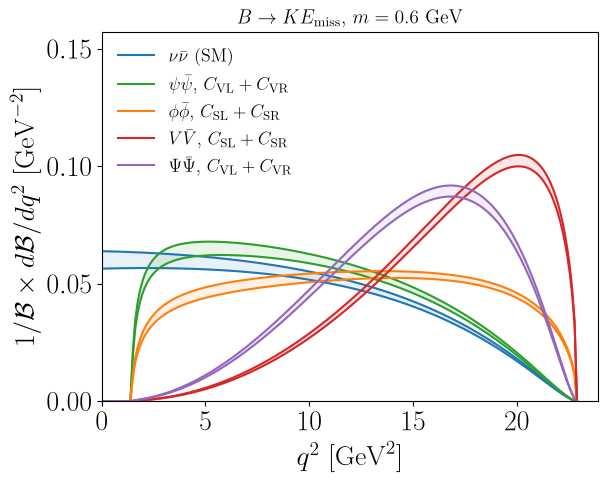

In [5]:
def plot_band(axes, band, color, ls = '-'):
    "Mean +- standard deviation band, returns the line for the legend."
    mean, std = band
    line, = axes.plot(qsq_vals, mean + std, color = color, ls = ls)
    axes.plot(qsq_vals, mean - std, color = color, ls = ls)
    axes.fill_between(qsq_vals, mean - std, mean + std, color = color, alpha = 0.1)
    return line

fig, axes = plt.subplots(nrows = 1, ncols = 1)
lines = {r'$\nu\bar{\nu}$ (SM)': plot_band(axes, band_SM, 'C0')}
for label, color in zip(models, ('C2', 'C1', 'C3', 'C4')):
    lines[label] = plot_band(axes, bands[label], color)

axes.set_xlim(0, q2_max + 1)
axes.set_ylim(0, 1.5 * max((mean + std).max() for mean, std in [band_SM, *bands.values()]))
axes.set_xlabel(r'$q^2 ~[\mathrm{GeV}^2]$')
axes.set_ylabel(r'$1/\mathcal{B} \times d\mathcal{B}/dq^2 ~[\mathrm{GeV}^{-2}]$')
axes.legend(lines.values(), lines.keys(), loc = 'upper left', fontsize = 13, frameon = False)
axes.set_title(r'$B\to K E_{\mathrm{miss}}$, $m = %g$ GeV' % m, fontsize = 14)
fig.set_size_inches(6.4, 4.8)

## SM + new physics at the best-fit coupling

Each scenario's couplings are fitted to Belle II, BaBar and LEP (`best_fit_model`), with $\mu_{\rm SM} = 1$; the SM and new physics rates add, so the scenarios must not interfere with the SM (true for invisible particles, and for the scalar and tensor WET operators). The vector WET couplings $C_{\rm VL}$ and $C_{\rm VR}$ do interfere with the SM: they are fitted with `fit_WET_vector`, which includes the SM in them, and the plotted rate is the total one. As in Fig. 4 of [arXiv:2503.19025](https://arxiv.org/abs/2503.19025), each channel is divided by its total SM branching fraction.

The bands combine the form factor uncertainties (the toys above, varying the SM and new physics rates together) with the uncertainty of the fitted coupling: each toy also draws the coupling multiplier from the Gaussian of the fit. The coupling uncertainty dominates.

In [6]:
from matplotlib.lines import Line2D
from lights.fits import best_fit_model, fit_WET_vector
from lights.constants import CVL_SM
from lights.constants import mKs
from lights.models import KS

# SM toys of 1/B_SM x dB/dq^2 for B -> K and B -> K*, normalised by their total SM branching fractions
BR_SM_Ks = quad(lambda qsq: dBdqsq_SM(qsq)[KS], 1e-12, (mB - mKs)**2)[0]
norm = np.array([BR_SM, BR_SM_Ks])
SM_toys = np.array([dBdqsq_SM(qsq_vals, a_vals = a_vals)[[K, KS]] for a_vals in a_vals_r]) / norm[:, None]

def latex_pm(value, error):
    "value +- error in LaTeX, with a common power of ten if needed."
    n = int(np.floor(np.log10(abs(value))))
    if -2 <= n <= 2:
        return r'%.2g \pm %.2g' % (value, error)
    return r'(%.2g \pm %.2g) \times 10^{%d}' % (value / 10**n, error / 10**n, n)

def plot_best_fit(model, label, coupling, color, particle = None):
    """Fit the coupling multiplier of model (combined fit) and plot SM + NP and SM for B -> K and B -> K*.

    label: the NP legend entry; coupling: LaTeX of the fitted coupling (the sum of the model's couplings,
    which are scaled together); particle: LaTeX symbol for the mass in the title (None: no mass and Lambda).
    """
    best, fit = best_fit_model("combined", model)
    unit = sum(model.couplings.values())   # the coupling at multiplier 1
    print(f"{model}: best-fit multiplier {fit.value:.3g} +- {fit.error:.2g}, -2 ln(L_SM+NP / L_SM) = {fit.delta_chi2:.1f}")

    # NP toys: the coupling multiplier from the Gaussian of the fit (fixed seed), rates proportional to x^2
    x_toys = np.random.default_rng(2).normal(fit.value, fit.error, len(a_vals_r))
    NP_toys = np.array([x**2 * model.dBdqsq(qsq_vals, a_vals)[[K, KS]] for x, a_vals in zip(x_toys, a_vals_r)]) / norm[:, None]
    title = r'$%s = %s$ (best fit)' % (coupling, latex_pm(abs(fit.value) * unit, fit.error * abs(unit)))
    if particle is not None:
        title += r', $m_%s = %g$ GeV, $\Lambda = %g$ TeV' % (particle, best.mX, best.Lambda / 1e3)
    plot_spectra(SM_toys + NP_toys, label, color, title)
    return best, fit

def plot_spectra(toys, label, color, title):
    """Plot the SM and the given toys of 1/B_SM x dB/dq^2 (shape (toys, 2, q^2): B -> K, B -> K*) as bands."""
    bands = {(name, row): (t[:, i].mean(axis = 0), t[:, i].std(axis = 0))
             for name, t in (("SM+NP", toys), ("SM", SM_toys)) for i, row in enumerate((K, KS))}
    fig, axes = plt.subplots(nrows = 1, ncols = 1)
    for (name, row), band in bands.items():
        plot_band(axes, band, color if name == "SM+NP" else 'C0', '-' if row == K else '--')
    axes.set_xlim(0, q2_max + 1)
    axes.set_ylim(0, 1.35 * max((mean + std).max() for mean, std in bands.values()))   # room for the legend
    axes.set_xlabel(r'$q^2 ~[\mathrm{GeV}^2]$')
    axes.set_ylabel(r'$1/\mathcal{B}_{\rm SM} \times d\mathcal{B}/dq^2 ~[\mathrm{GeV}^{-2}]$')
    axes.legend([Line2D([], [], color = color), Line2D([], [], color = 'C0'), Line2D([], [], color = 'k', ls = '-'),
                 Line2D([], [], color = 'k', ls = '--')],
                [label, 'SM only', r'$B\to K E_{\mathrm{miss}}$', r'$B\to K^* E_{\mathrm{miss}}$'],
                loc = 'upper right', ncol = 2, fontsize = 14, frameon = False)
    axes.set_title(title, fontsize = 14)
    fig.set_size_inches(6.4, 4.8)

Model('psipsi', mX = 0.6, Lambda = 10000, CVL = 1, CVR = 1): best-fit multiplier 1.73 +- 0.25, -2 ln(L_SM+NP / L_SM) = -12.0


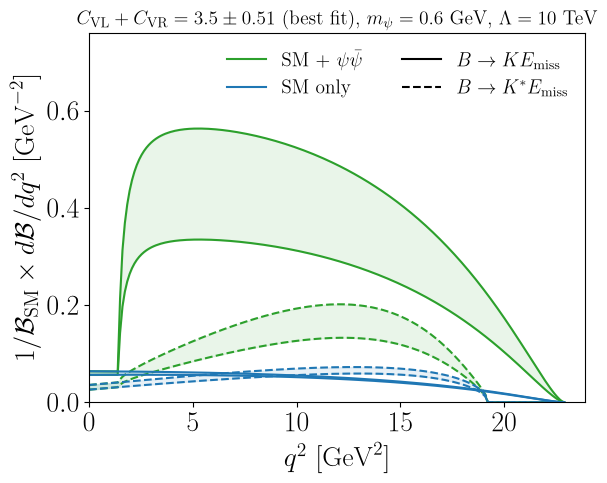

In [7]:
# Fermions, vector currents, at the best-fit mass
best, fit = plot_best_fit(Model("psipsi", 0.6, Lambda = 1e4, CVL = 1., CVR = 1.), r'SM + $\psi\bar\psi$',
                          r'C_{\rm VL} + C_{\rm VR}', 'C2', particle = r'\psi')

Model('phiphi', mX = 0.53, Lambda = 10000, CSL = 0.001, CSR = 0.001): best-fit multiplier 0.775 +- 0.12, -2 ln(L_SM+NP / L_SM) = -9.9


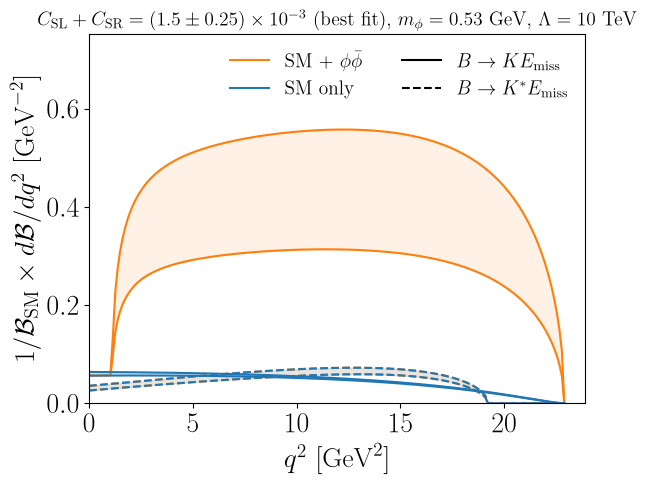

In [8]:
# Scalars, scalar currents, at the best-fit mass
best, fit = plot_best_fit(Model("phiphi", 0.53, Lambda = 1e4, CSL = 1e-3, CSR = 1e-3), r'SM + $\phi\bar\phi$',
                          r'C_{\rm SL} + C_{\rm SR}', 'C1', particle = r'\phi')

Model('phiphi', mX = 0.38, Lambda = 10000, CVL = 1, CVR = 1): best-fit multiplier 3.56 +- 0.56, -2 ln(L_SM+NP / L_SM) = -10.3


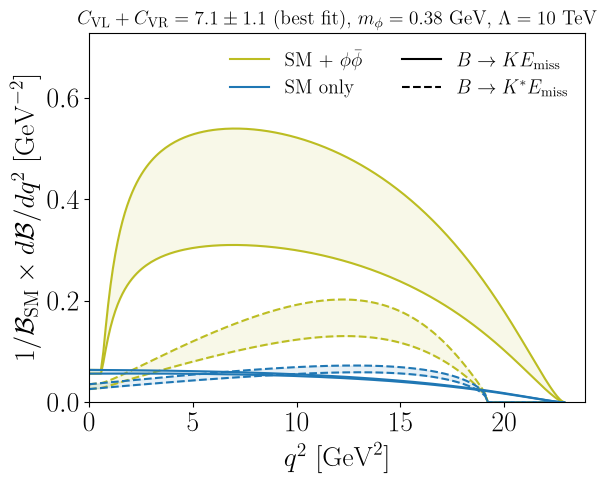

In [9]:
# Scalars, vector currents, at the best-fit mass
best, fit = plot_best_fit(Model("phiphi", 0.38, Lambda = 1e4, CVL = 1., CVR = 1.), r'SM + $\phi\bar\phi$',
                          r'C_{\rm VL} + C_{\rm VR}', 'C8', particle = r'\phi')

Model('nunu', mX = 0, CTL = 1): best-fit multiplier 3.07 +- 1.6, -2 ln(L_SM+NP / L_SM) = -1.2


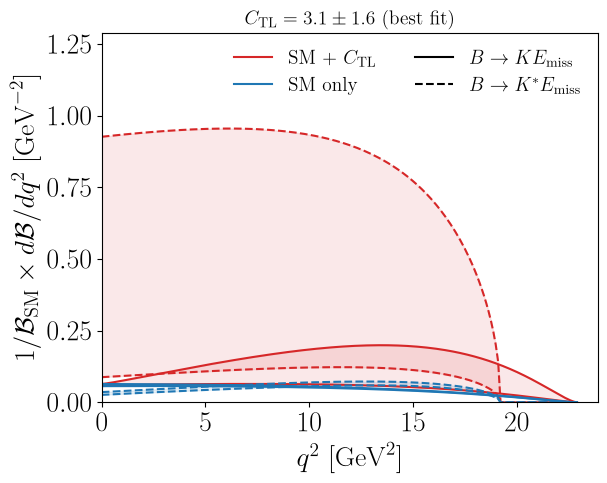

In [10]:
# Weak effective theory: the tensor operator (C_TL, normalised as in arXiv:2507.12393), which does not interfere with the SM
best, fit = plot_best_fit(Model("nunu", 0., CTL = 1.), r'SM + $C_{\rm TL}$', r'C_{\rm TL}', 'C3')

best fit: C_VR = 8.32 +- 2.34 (C_VL = 6.60, SM), -2 ln(L / L_SM) = -6.6


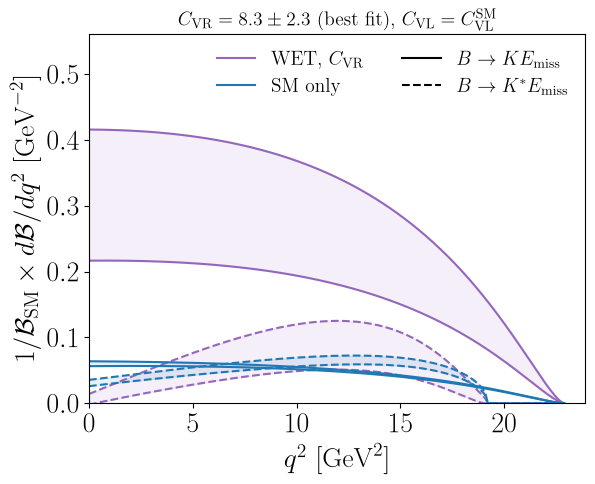

In [11]:
# Weak effective theory: a right-handed vector current C_VR, with C_VL at its SM value. C_VR interferes with the SM:
# fit_WET_vector includes the SM in the couplings, and the toys are of the total rate
wet = fit_WET_vector("combined", CVL = CVL_SM)
print(f"best fit: C_VR = {wet.CVR:.2f} +- {wet.errors[1]:.2f} (C_VL = {wet.CVL:.2f}, SM), -2 ln(L / L_SM) = {wet.delta_chi2:.1f}")
CVR_toys = np.random.default_rng(2).normal(wet.CVR, wet.errors[1], len(a_vals_r))
WET_toys = np.array([Model("nunu", 0., CVL = CVL_SM, CVR = CVR).dBdqsq(qsq_vals, a_vals)[[K, KS]]
                     for CVR, a_vals in zip(CVR_toys, a_vals_r)]) / norm[:, None]
plot_spectra(WET_toys, r'WET, $C_{\rm VR}$', 'C4',
             r'$C_{\rm VR} = %s$ (best fit), $C_{\rm VL} = C_{\rm VL}^{\rm SM}$' % latex_pm(wet.CVR, wet.errors[1]))